# Notebook 4 — Analisis Gabungan Marine Heatwave (MHW) dan Respons Biogeokimia Chlorophyll-a

**Proyek:** Analisis Spatiotemporal Marine Heatwaves (MHW), Klorofil-a, dan Konteks Perikanan Tangkap Provinsi Nusa Tenggara Timur  
**Dokumen Rujukan Metodologis:** `REVISI_PBL.md`

---

## 1. Landasan Metodologis Analisis Gabungan

1. **Penyelarasan Spasial Konservatif (Conservative Regridding):**
   - Data klorofil-a asli beresolusi ~4 km diagregasikan secara spasial ke grid 0.25° OISST melalui teknik *block-averaging* tanpa pengisian nol palsu (`NaN` dipertahankan).
2. **Standardisasi Perbandingan MHW vs Non-MHW:**
   - Kondisi non-MHW didefinisikan secara ketat sebagai hari-hari yang terbebas dari kondisi MHW (*MHW-free days*) pada sel grid yang bersangkutan.
   - Perbandingan distribusi klorofil-a diuji secara statistik menggunakan uji non-parametrik Mann-Whitney U untuk memvalidasi apakah penurunan klorofil selama MHW signifikan secara statistik ($p < 0.05$).
3. **Analisis Fase Kejadian Terstandarisasi (Event Phase Analysis):**
   - Untuk kejadian MHW regional signifikan (studi kasus peristiwa 2016 yang merupakan MHW terpanjang dalam rekor pengamatan), analisis dibagi ke dalam 3 jendela waktu terstandarisasi:
     - **Fase Pra-MHW:** 14 hari sebelum kejadian dimulai ($T_{	ext{start}} - 14$ s.d. $T_{	ext{start}} - 1$).
     - **Fase Puncak MHW:** Jendela di sekitar hari intensitas maksimum ($T_{	ext{peak}} \pm 7$ hari).
     - **Fase Pasca-MHW:** 14 hari setelah kejadian berakhir ($T_{	ext{end}} + 1$ s.d. $T_{	ext{end}} + 14$).
   - Dilengkapi pelaporan persentase tutupan piksel observasi valid (*valid pixel coverage ratio*) untuk mengontrol bias tutupan awan.


---
## 1. Konfigurasi dan Impor Pustaka

In [1]:
import sys
import os
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# Tambahkan path folder config dan scripts revisi
notebook_dir = Path(os.path.abspath('')).resolve()
current = notebook_dir
while current != current.parent:
    if (current / 'config' / 'project_config.py').exists():
        project_root = current
        break
    current = current.parent
else:
    project_root = Path(r"G:\My Drive\KLIMTROP\PBL")


if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
if str(project_root / 'config') not in sys.path:
    sys.path.insert(0, str(project_root / 'config'))

if 'project_config' in sys.modules:
    del sys.modules['project_config']

import project_config as cfg

print("=" * 60)
print("KONFIGURASI NOTEBOOK 4 — ANALISIS GABUNGAN MHW & CHL-A")
print("=" * 60)
print(f"SST Merged Input : {cfg.SST_MERGED_OUTPUT}")
print(f"Chl-a Merged Input: {cfg.CHLA_MERGED_OUTPUT}")
print(f"MHW Events Input : {cfg.MHW_EVENTS_OUTPUT}")
print(f"Combined Output  : {cfg.COMBINED_OUTPUT}")
print(f"Grid Referensi   : {cfg.COMBINED_GRID} (0.25°)")

KONFIGURASI NOTEBOOK 4 — ANALISIS GABUNGAN MHW & CHL-A
SST Merged Input : G:\My Drive\KLIMTROP\PBL\data\processed\sst_daily_2000_2020_ntt.nc
Chl-a Merged Input: G:\My Drive\KLIMTROP\PBL\data\processed\chlorophyll_a_daily_ntt.nc
MHW Events Input : G:\My Drive\KLIMTROP\PBL\data\processed\mhw_events_ntt.csv
Combined Output  : G:\My Drive\KLIMTROP\PBL\data\processed\mhw_chla_aligned_daily_ntt.nc
Grid Referensi   : sst (0.25°)


### Utilitas Visualisasi (Inline)

In [2]:
# ================================================================
# UTILITAS VISUALISASI (di-inline dari visualization_utils.py)
# ================================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import LogNorm, Normalize, BoundaryNorm
from scipy.ndimage import map_coordinates, gaussian_filter
from pathlib import Path

try:
    import geopandas as gpd
    HAS_GEOPANDAS = True
except ImportError:
    HAS_GEOPANDAS = False

# Path GeoJSON batas daratan pulau NTT
_vz_root = globals().get('project_root') or globals().get('PROJECT_ROOT') or (getattr(cfg, 'PROJECT_ROOT', None) if 'cfg' in globals() else None)
if _vz_root is None:
    _vz_root = Path('.').resolve()
COASTLINE_GEOJSON = _vz_root / "dashboard" / "data" / "ntt_coastline.geojson"
if not COASTLINE_GEOJSON.exists():
    for _cand in [_vz_root.parent / "dashboard" / "data" / "ntt_coastline.geojson"]:
        if _cand.exists():
            COASTLINE_GEOJSON = _cand
            break

_CACHED_LAND_GDF = None

def load_ntt_coastline():
    """Memuat dan meng-cache GeoDataFrame poligon daratan kepulauan NTT."""
    global _CACHED_LAND_GDF
    if _CACHED_LAND_GDF is not None:
        return _CACHED_LAND_GDF
    if HAS_GEOPANDAS and COASTLINE_GEOJSON.exists():
        try:
            _CACHED_LAND_GDF = gpd.read_file(COASTLINE_GEOJSON)
            return _CACHED_LAND_GDF
        except Exception as e:
            print(f"Warning: Gagal memuat ntt_coastline.geojson: {e}")
            return None
    return None

def add_land_mask(ax, gdf_land=None, facecolor="#e4e4e4", edgecolor="#3a3a3a", linewidth=0.6, zorder=5):
    """Menambahkan poligon pulau-pulau NTT ke axis Matplotlib."""
    if gdf_land is None:
        gdf_land = load_ntt_coastline()
    if gdf_land is not None:
        gdf_land.plot(ax=ax, facecolor=facecolor, edgecolor=edgecolor, linewidth=linewidth, zorder=zorder)

def setup_spatial_axis(ax, lon_extent=None, lat_extent=None, title=None, fontsize_title=11, xlabel="Bujur (°BT)", ylabel="Lintang (°LS)"):
    """Format sumbu kartografi standar dengan label koordinat presisi dan grid tipis."""
    if lon_extent is not None:
        ax.set_xlim(lon_extent)
    if lat_extent is not None:
        ax.set_ylim(lat_extent)
    ax.set_aspect("equal")
    ax.grid(True, linestyle=":", alpha=0.35, color="gray", zorder=1)
    if title:
        ax.set_title(title, fontsize=fontsize_title, fontweight="bold", pad=7)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=9.5)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=9.5)
    ax.tick_params(axis="both", labelsize=8.5)

def refine_field(lon, lat, data, factor="auto", sigma_frac=0.45, min_weight=0.5, target_step=0.05):
    """
    Memperhalus medan 2D beresolusi kasar agar kontur tidak kotak-kotak.
    Metode: interpolasi bilinear + gaussian dengan pembobotan sadar-NaN.
    """
    lon = np.asarray(lon, dtype=float)
    lat = np.asarray(lat, dtype=float)
    arr = np.asarray(data, dtype=float)
    if factor == "auto":
        step = max(float(np.nanmedian(np.abs(np.diff(lon)))) if lon.size > 1 else target_step, 1e-9)
        factor = int(min(8, max(1, round(step / target_step))))
    factor = int(factor)
    if factor <= 1 or arr.ndim != 2 or arr.shape[0] < 2 or arr.shape[1] < 2:
        return lon, lat, arr
    ny, nx = arr.shape
    valid = np.isfinite(arr)
    filled = np.where(valid, arr, 0.0)
    yy = np.linspace(0, ny - 1, (ny - 1) * factor + 1)
    xx = np.linspace(0, nx - 1, (nx - 1) * factor + 1)
    gy, gx = np.meshgrid(yy, xx, indexing="ij")
    num = map_coordinates(filled, [gy, gx], order=1, mode="nearest")
    den = map_coordinates(valid.astype(float), [gy, gx], order=1, mode="nearest")
    sigma = sigma_frac * factor
    if sigma > 0:
        num = gaussian_filter(num, sigma, mode="nearest")
        den = gaussian_filter(den, sigma, mode="nearest")
    with np.errstate(all="ignore"):
        out = np.where(den >= min_weight, num / den, np.nan)
    lon_f = np.interp(xx, np.arange(nx), lon)
    lat_f = np.interp(yy, np.arange(ny), lat)
    return lon_f, lat_f, out

def plot_smooth_map(ax, lon, lat, data, var_type="continuous", cmap="coolwarm",
                    vmin=None, vmax=None, norm=None, levels=35, title=None,
                    cbar=True, cbar_label="", cbar_shrink=0.8, cbar_fraction=0.046,
                    cbar_pad=0.04, extend="both", gdf_land=None,
                    land_color="#e4e4e4", land_edge="#3a3a3a", refine="auto"):
    """Merender peta spasial berkualitas tinggi dengan overlay garis pantai NTT."""
    if gdf_land is None:
        gdf_land = load_ntt_coastline()
    lon_min, lon_max = float(np.nanmin(lon)), float(np.nanmax(lon))
    lat_min, lat_max = float(np.nanmin(lat)), float(np.nanmax(lat))
    if refine:
        lon, lat, data = refine_field(lon, lat, data, factor=refine)
    if var_type == "continuous":
        if vmin is None: vmin = float(np.nanmin(data))
        if vmax is None: vmax = float(np.nanmax(data))
        contour_levels = np.linspace(vmin, vmax, levels)
        cs = ax.contourf(lon, lat, data, levels=contour_levels, cmap=cmap, vmin=vmin, vmax=vmax, extend=extend, zorder=2)
    elif var_type == "log":
        if norm is None:
            norm = LogNorm(vmin=vmin if vmin is not None else 0.05, vmax=vmax if vmax is not None else 2.5)
        log_levels = np.geomspace(norm.vmin, norm.vmax, levels)
        cs = ax.contourf(lon, lat, data, levels=log_levels, cmap=cmap, norm=norm, extend=extend, zorder=2)
    elif var_type == "discrete":
        d_min = int(np.floor(np.nanmin(data))) if vmin is None else int(vmin)
        d_max = int(np.ceil(np.nanmax(data))) if vmax is None else int(vmax)
        discrete_levels = np.arange(d_min - 0.5, d_max + 1.5, 1.0)
        norm_disc = BoundaryNorm(discrete_levels, ncolors=256)
        cs = ax.contourf(lon, lat, data, levels=discrete_levels, cmap=cmap, norm=norm_disc, zorder=2)
    elif var_type == "binary":
        cs = ax.contourf(lon, lat, data, levels=[-0.5, 0.5, 1.5], cmap=cmap, vmin=0, vmax=1, zorder=2)
    else:
        cs = ax.pcolormesh(lon, lat, data, cmap=cmap, vmin=vmin, vmax=vmax, shading="auto", zorder=2)
    add_land_mask(ax, gdf_land=gdf_land, facecolor=land_color, edgecolor=land_edge, linewidth=0.6, zorder=5)
    setup_spatial_axis(ax, (lon_min, lon_max), (lat_min, lat_max), title=title)
    cb = None
    if cbar:
        cb = plt.colorbar(cs, ax=ax, shrink=cbar_shrink, fraction=cbar_fraction, pad=cbar_pad)
        if cbar_label:
            cb.set_label(cbar_label, fontsize=9)
        cb.ax.tick_params(labelsize=8)
        if var_type == "continuous":
            cb.locator = ticker.MaxNLocator(nbins=6)
            cb.update_ticks()
    return cs, cb

print("✅ Utilitas visualisasi siap.")

✅ Utilitas visualisasi siap.


### Fungsi Deteksi MHW & Analisis Grid (Inline)

In [3]:
# ================================================================
# FUNGSI DETEKSI MHW DAN ANALISIS GRID
# (di-inline dari detect_mhw.py dan mhw_grid_analysis.py)
# ================================================================
import numpy as np
import pandas as pd
from scipy.ndimage import uniform_filter1d
from scipy import stats

# ---------------------- Deteksi MHW (dari detect_mhw.py) ----------------------

def compute_climatology_and_threshold(time_index, sst_series, window_half=15, pct=90, smooth_window=31, doy=None):
    """Menghitung klimatologi harian dan ambang persentil ke-90 musiman (Hobday et al. 2016)."""
    if doy is None:
        doy = time_index.day_of_year.values
    sst = np.asarray(sst_series, dtype=np.float32)
    clim_raw = np.full(366, np.nan, dtype=np.float32)
    thresh_raw = np.full(366, np.nan, dtype=np.float32)
    valid_mask = ~np.isnan(sst)
    if not np.any(valid_mask):
        return clim_raw, thresh_raw
    for d in range(1, 367):
        d_min = (d - window_half - 1) % 366 + 1
        d_max = (d + window_half - 1) % 366 + 1
        in_window = (doy >= d_min) & (doy <= d_max) if d_min <= d_max else (doy >= d_min) | (doy <= d_max)
        vals = sst[in_window & valid_mask]
        if len(vals) >= 10:
            clim_raw[d-1] = np.mean(vals)
            thresh_raw[d-1] = np.percentile(vals, pct)
    if np.isnan(clim_raw[365]) and not np.isnan(clim_raw[364]):
        clim_raw[365] = (clim_raw[364] + clim_raw[0]) / 2.0
        thresh_raw[365] = (thresh_raw[364] + thresh_raw[0]) / 2.0
    return uniform_filter1d(clim_raw, size=smooth_window, mode="wrap"), uniform_filter1d(thresh_raw, size=smooth_window, mode="wrap")


def detect_mhw_events_1d(time_index, sst_series, clim_doy, thresh_doy, min_duration=5, max_gap=2, doy=None):
    """Mendeteksi kejadian MHW pada 1 titik deret waktu (Hobday et al. 2016)."""
    if doy is None:
        doy = time_index.day_of_year.values
    sst = np.asarray(sst_series, dtype=np.float32)
    n_days = len(sst)
    clim_ts = clim_doy[doy - 1]
    thresh_ts = thresh_doy[doy - 1]
    is_above = (sst > thresh_ts) & (~np.isnan(sst))
    events, in_event, start_idx = [], False, None
    for i in range(n_days):
        if is_above[i] and not in_event:
            in_event, start_idx = True, i
        elif not is_above[i] and in_event:
            in_event = False
            events.append((start_idx, i - 1))
    if in_event:
        events.append((start_idx, n_days - 1))
    merged_events = []
    if events:
        curr_start, curr_end = events[0]
        for next_start, next_end in events[1:]:
            gap = next_start - curr_end - 1
            if gap <= max_gap and np.all(sst[curr_end+1:next_start] > clim_ts[curr_end+1:next_start]):
                curr_end = next_end
            else:
                merged_events.append((curr_start, curr_end))
                curr_start, curr_end = next_start, next_end
        merged_events.append((curr_start, curr_end))
    final_events = []
    is_mhw_ts = np.zeros(n_days, dtype=bool)
    for s_idx, e_idx in merged_events:
        duration = e_idx - s_idx + 1
        if duration >= min_duration:
            is_mhw_ts[s_idx:e_idx+1] = True
            anom = sst[s_idx:e_idx+1] - clim_ts[s_idx:e_idx+1]
            delta_thresh = thresh_ts[s_idx:e_idx+1] - clim_ts[s_idx:e_idx+1]
            i_max = float(np.max(anom))
            peak_offset = int(np.argmax(anom))
            ratio = i_max / delta_thresh[peak_offset] if delta_thresh[peak_offset] > 0 else 1.0
            cat_map = [(2.0, "I (Moderat)", 1), (3.0, "II (Kuat)", 2), (4.0, "III (Parah)", 3)]
            cat, cat_num = "IV (Ekstrem)", 4
            for lim, name, num in cat_map:
                if ratio < lim:
                    cat, cat_num = name, num
                    break
            final_events.append({
                "event_id": len(final_events) + 1,
                "start_date": str(time_index[s_idx].date()), "end_date": str(time_index[e_idx].date()),
                "peak_date": str(time_index[s_idx + peak_offset].date()),
                "duration_days": int(duration), "i_max": round(i_max, 3),
                "i_mean": round(float(np.mean(anom)), 3), "i_cum": round(float(np.sum(anom)), 3),
                "category": cat, "category_num": cat_num, "start_idx": s_idx, "end_idx": e_idx
            })
    return pd.DataFrame(final_events), clim_ts, thresh_ts, is_mhw_ts


def run_spatial_mhw_detection(ds_sst, regional_extent_threshold=0.15, verbose=True):
    """Menjalankan analisis MHW penuh secara spasial (per sel grid 0.25°) pada seluruh perairan NTT."""
    sst_data = ds_sst["sst"].values
    n_time, n_lat, n_lon = sst_data.shape
    time_index = pd.DatetimeIndex(ds_sst.time.values)
    doy = time_index.day_of_year.values
    lats, lons = ds_sst.lat.values, ds_sst.lon.values
    if verbose:
        print(f"Memulai Deteksi MHW Grid-by-Grid NTT ({n_lat} x {n_lon} grid, {n_time} hari)...")
    spatial_clim = np.full((366, n_lat, n_lon), np.nan, dtype=np.float32)
    spatial_thresh = np.full((366, n_lat, n_lon), np.nan, dtype=np.float32)
    spatial_mhw_days = np.zeros((n_lat, n_lon), dtype=np.float32)
    spatial_mhw_events_count = np.zeros((n_lat, n_lon), dtype=np.int32)
    spatial_max_intensity = np.zeros((n_lat, n_lon), dtype=np.float32)
    spatial_mean_intensity = np.zeros((n_lat, n_lon), dtype=np.float32)
    is_mhw_3d = np.zeros((n_time, n_lat, n_lon), dtype=bool)
    intensity_3d = np.zeros((n_time, n_lat, n_lon), dtype=np.float32)
    ocean_mask = ~np.isnan(sst_data[0])
    total_ocean_cells = int(np.sum(ocean_mask))
    if verbose:
        print(f"Total sel laut terdeteksi: {total_ocean_cells} sel grid.")
    local_events_list = []
    for j in range(n_lat):
        for i in range(n_lon):
            pix_sst = sst_data[:, j, i]
            if np.isnan(pix_sst).all():
                continue
            c_doy, t_doy = compute_climatology_and_threshold(
                time_index, pix_sst, window_half=15,
                pct=cfg.MHW_PERCENTILE, smooth_window=cfg.MHW_SMOOTHING_WINDOW, doy=doy)
            spatial_clim[:, j, i] = c_doy
            spatial_thresh[:, j, i] = t_doy
            df_ev, c_ts, t_ts, is_mhw_ts = detect_mhw_events_1d(
                time_index, pix_sst, c_doy, t_doy,
                min_duration=cfg.MHW_MIN_DURATION_DAYS, max_gap=2, doy=doy)
            is_mhw_3d[:, j, i] = is_mhw_ts
            anom = pix_sst - c_ts
            intensity_3d[:, j, i] = np.where(is_mhw_ts, anom, 0.0)
            if len(df_ev) > 0:
                spatial_mhw_days[j, i] = df_ev["duration_days"].sum()
                spatial_mhw_events_count[j, i] = len(df_ev)
                spatial_max_intensity[j, i] = df_ev["i_max"].max()
                spatial_mean_intensity[j, i] = df_ev["i_mean"].mean()
                for _, row in df_ev.iterrows():
                    rd = row.to_dict(); rd["lat"] = float(lats[j]); rd["lon"] = float(lons[i])
                    local_events_list.append(rd)
    spatial_mhw_days[~ocean_mask] = np.nan
    spatial_mhw_events_count[~ocean_mask] = -1
    spatial_max_intensity[~ocean_mask] = np.nan
    spatial_mean_intensity[~ocean_mask] = np.nan
    df_local_events = pd.DataFrame(local_events_list)
    daily_mhw_cells = np.sum(is_mhw_3d[:, ocean_mask], axis=1)
    daily_extent_ratio = daily_mhw_cells / float(total_ocean_cells)
    is_regional_mhw_day = daily_extent_ratio >= regional_extent_threshold
    reg_events, in_reg, start_idx = [], False, None
    for t in range(n_time):
        if is_regional_mhw_day[t] and not in_reg:
            in_reg, start_idx = True, t
        elif not is_regional_mhw_day[t] and in_reg:
            in_reg = False
            reg_events.append((start_idx, t - 1))
    if in_reg:
        reg_events.append((start_idx, n_time - 1))
    merged_reg = []
    if reg_events:
        cs, ce = reg_events[0]
        for ns, ne in reg_events[1:]:
            if ns - ce - 1 <= 2: ce = ne
            else: merged_reg.append((cs, ce)); cs, ce = ns, ne
        merged_reg.append((cs, ce))
    final_reg_events = []
    for s_idx, e_idx in merged_reg:
        duration = e_idx - s_idx + 1
        if duration >= cfg.MHW_MIN_DURATION_DAYS:
            ev_extents = daily_extent_ratio[s_idx:e_idx+1]
            peak_offset = int(np.argmax(ev_extents))
            peak_idx = s_idx + peak_offset
            ev_intensities = intensity_3d[s_idx:e_idx+1]
            active_intensities = ev_intensities[ev_intensities > 0]
            final_reg_events.append({
                "regional_event_id": len(final_reg_events) + 1,
                "start_date": str(time_index[s_idx].date()), "end_date": str(time_index[e_idx].date()),
                "peak_date": str(time_index[peak_idx].date()),
                "duration_days": int(duration),
                "peak_extent_pct": round(float(np.max(ev_extents) * 100), 2),
                "mean_extent_pct": round(float(np.mean(ev_extents) * 100), 2),
                "i_max_regional": round(float(np.max(active_intensities)) if len(active_intensities) > 0 else 0.0, 3),
                "i_mean_regional": round(float(np.mean(active_intensities)) if len(active_intensities) > 0 else 0.0, 3),
                "cum_intensity_regional": round(float(np.sum(active_intensities)), 1),
                "start_idx": s_idx, "end_idx": e_idx
            })
    df_regional_events = pd.DataFrame(final_reg_events)
    if verbose:
        print(f"Deteksi selesai: {len(df_local_events)} kejadian lokal, {len(df_regional_events)} kejadian regional NTT.")
    return {
        "spatial_clim": spatial_clim, "spatial_thresh": spatial_thresh,
        "spatial_mhw_days": spatial_mhw_days, "spatial_mhw_events_count": spatial_mhw_events_count,
        "spatial_max_intensity": spatial_max_intensity, "spatial_mean_intensity": spatial_mean_intensity,
        "is_mhw_3d": is_mhw_3d, "intensity_3d": intensity_3d,
        "daily_extent_ratio": daily_extent_ratio, "df_local_events": df_local_events,
        "df_regional_events": df_regional_events, "ocean_mask": ocean_mask,
        "total_ocean_cells": total_ocean_cells
    }


# ---------------------- Analisis Grid MHW (dari mhw_grid_analysis.py) ----------------------

SEASONS = {
    "DJF (Monsun Barat)": [12, 1, 2],
    "MAM (Peralihan I)": [3, 4, 5],
    "JJA (Monsun Timur / Upwelling)": [6, 7, 8],
    "SON (Peralihan II)": [9, 10, 11],
}

def simple_daily_climatology(sst, doy):
    """Rata-rata SST per hari-ke-tahun (1..366) per grid. sst: (time, lat, lon); doy: (time,) -> (366, lat, lon)."""
    out = np.full((366,) + sst.shape[1:], np.nan, dtype=np.float32)
    for d in range(1, 367):
        sel = doy == d
        if sel.any():
            with np.errstate(all="ignore"):
                out[d - 1] = np.nanmean(sst[sel], axis=0)
    return out

def longest_run(flag3d):
    """Panjang run True beruntun terpanjang sepanjang sumbu waktu, per grid."""
    cur = np.zeros(flag3d.shape[1:], dtype=np.int32)
    best = np.zeros_like(cur)
    for t in range(flag3d.shape[0]):
        cur = np.where(flag3d[t], cur + 1, 0)
        best = np.maximum(best, cur)
    return best

def event_window_maps(sst, doy, daymean, strict, member, intensity_3d, s_idx, e_idx):
    """Peta per grid untuk satu kejadian (jendela indeks waktu s_idx..e_idx inklusif)."""
    sl = slice(int(s_idx), int(e_idx) + 1)
    daily_anom = sst[sl] - daymean[doy[sl] - 1]
    with np.errstate(all="ignore"):
        anomaly_mean = np.nanmean(daily_anom, axis=0)
        anomaly_max = np.nanmax(np.where(np.isfinite(daily_anom), daily_anom, -np.inf), axis=0)
    return {
        "anomaly_mean": anomaly_mean.astype(np.float32),
        "anomaly_max": np.where(np.isfinite(anomaly_max), anomaly_max, np.nan).astype(np.float32),
        "duration_run": longest_run(member[sl]).astype(np.float32),
        "mhw_days": strict[sl].sum(axis=0).astype(np.float32),
        "intensity_max": np.max(intensity_3d[sl], axis=0).astype(np.float32),
    }

def classify_mhw_days(is_mhw_3d, sst, thresh_doy, doy):
    """Pisahkan anggota kejadian menjadi hari MHW sebenarnya (strict) dan hari jeda (gap)."""
    thr_t = thresh_doy[doy - 1]
    strict = is_mhw_3d & np.isfinite(sst) & (sst > thr_t)
    return strict, is_mhw_3d & ~strict

def daily_extent(member, strict, ocean_mask):
    n = float(ocean_mask.sum())
    return member[:, ocean_mask].sum(axis=1) / n, strict[:, ocean_mask].sum(axis=1) / n

def redetect_regional_events(member_ratio, threshold=0.15, min_duration=5, max_gap=2):
    """Deteksi ulang kejadian regional dari rasio cakupan harian."""
    flag = member_ratio >= threshold
    blocks, in_b, s = [], False, 0
    for t, f in enumerate(flag):
        if f and not in_b: in_b, s = True, t
        elif not f and in_b: in_b = False; blocks.append((s, t - 1))
    if in_b: blocks.append((s, len(flag) - 1))
    merged = []
    for b in blocks:
        if merged and b[0] - merged[-1][1] - 1 <= max_gap: merged[-1] = (merged[-1][0], b[1])
        else: merged.append(b)
    return [(a, b) for a, b in merged if b - a + 1 >= min_duration]

def check_regional_catalog(df_reg, member_ratio, strict_ratio, time_index, threshold=0.15):
    """Periksa katalog regional terhadap data per grid."""
    rows = []
    for _, ev in df_reg.iterrows():
        s, e = int(ev["start_idx"]), int(ev["end_idx"])
        seg_m, seg_s = member_ratio[s:e + 1], strict_ratio[s:e + 1]
        reg = int((seg_m >= threshold).sum())
        rows.append({
            "regional_event_id": int(ev["regional_event_id"]), "start_date": ev["start_date"], "end_date": ev["end_date"],
            "durasi_katalog_hari": e - s + 1, "hari_mhw_regional": reg, "hari_jeda": (e - s + 1) - reg,
            "hari_strict_ge_ambang": int((seg_s >= threshold).sum()),
            "cakupan_maks_anggota_pct": round(float(seg_m.max() * 100), 2),
            "cakupan_maks_di_atas_p90_pct": round(float(seg_s.max() * 100), 2),
            "cakupan_puncak_katalog_pct": float(ev["peak_extent_pct"]),
        })
    df = pd.DataFrame(rows)
    det = redetect_regional_events(member_ratio, threshold)
    cat = set((int(a), int(b)) for a, b in zip(df_reg["start_idx"], df_reg["end_idx"]))
    summary = {
        "kejadian_katalog": len(df), "hari_durasi_katalog": int(df["durasi_katalog_hari"].sum()),
        "hari_mhw_regional": int(df["hari_mhw_regional"].sum()), "hari_jeda": int(df["hari_jeda"].sum()),
        "kejadian_deteksi_ulang": len(det), "cocok_persis": len(cat & set(det)),
    }
    return df, summary

def chl_baseline_doy(chl, member, doy, half=7):
    """Baseline klorofil per grid per hari-ke-tahun: rata-rata hari non-anggota kejadian."""
    ssum = np.zeros((366,) + chl.shape[1:], dtype=np.float64)
    scnt = np.zeros_like(ssum)
    ok = np.isfinite(chl) & ~member
    for d in range(1, 367):
        sel = doy == d
        if sel.any():
            v = np.where(ok[sel], chl[sel], 0.0)
            ssum[d - 1] = v.sum(axis=0)
            scnt[d - 1] = ok[sel].sum(axis=0)
    wsum, wcnt = np.zeros_like(ssum), np.zeros_like(scnt)
    for k in range(-half, half + 1):
        wsum += np.roll(ssum, k, axis=0)
        wcnt += np.roll(scnt, k, axis=0)
    with np.errstate(all="ignore"):
        return np.where(wcnt > 0, wsum / wcnt, np.nan).astype(np.float32)

def bh_fdr(p):
    """Koreksi FDR Benjamini-Hochberg pada array p (NaN diabaikan)."""
    p = np.asarray(p, dtype=float)
    q = np.full(p.shape, np.nan)
    idx = np.where(np.isfinite(p.ravel()))[0]
    if not len(idx): return q
    flat = p.ravel()[idx]
    order = np.argsort(flat)
    r = np.minimum.accumulate((flat[order] * len(flat) / np.arange(1, len(flat) + 1))[::-1])[::-1]
    qf = np.full(p.size, np.nan)
    qf[idx[order]] = np.minimum(r, 1.0)
    return qf.reshape(p.shape)

def per_grid_chl_response(chl, anom, strict, member, ocean_mask, month, min_n=10, alpha=0.05):
    """Perbandingan Chlorophyll a per grid: sel-hari MHW vs sel-hari non-MHW (Mann-Whitney U + FDR)."""
    valid_a = np.isfinite(anom)
    G_M, G_N = strict & valid_a, (~member) & valid_a
    results, pooled = {}, []
    groups = {"Seluruh Periode": np.ones(len(month), bool)}
    groups.update({k: np.isin(month, v) for k, v in SEASONS.items()})
    shape = chl.shape[1:]
    for name, sm in groups.items():
        M, N = G_M & sm[:, None, None], G_N & sm[:, None, None]
        n_m, n_n = M.sum(0), N.sum(0)
        with np.errstate(all="ignore"):
            chl_m = np.where(n_m > 0, np.where(M, chl, 0).sum(0) / np.maximum(n_m, 1), np.nan)
            chl_n = np.where(n_n > 0, np.where(N, chl, 0).sum(0) / np.maximum(n_n, 1), np.nan)
            anom_m = np.where(n_m > 0, np.where(M, anom, 0).sum(0) / np.maximum(n_m, 1), np.nan)
            base_m = np.where(n_m > 0, np.where(M, chl - anom, 0).sum(0) / np.maximum(n_m, 1), np.nan)
            pct = anom_m / base_m * 100.0
        p = np.full(shape, np.nan)
        for j, i in zip(*np.where(ocean_mask & (n_m >= min_n) & (n_n >= min_n))):
            p[j, i] = stats.mannwhitneyu(anom[M[:, j, i], j, i], anom[N[:, j, i], j, i], alternative="two-sided").pvalue
        q = bh_fdr(p)
        direction = np.where(np.isfinite(q), np.where(q < alpha, np.sign(anom_m), 0.0), np.nan)
        results[name] = {"n_mhw": np.where(ocean_mask, n_m, np.nan), "n_non": np.where(ocean_mask, n_n, np.nan),
                         "chl_mhw": chl_m, "chl_non": chl_n, "anom_mhw": anom_m, "pct": pct,
                         "p": p, "q": q, "direction": direction}
        ok = np.isfinite(q) & np.isfinite(anom_m)
        pooled.append({
            "Periode": name, "sel_diuji": int(ok.sum()), "sel_hari_mhw": int(M.sum()), "sel_hari_non_mhw": int(N.sum()),
            "chl_mhw_mean": float(np.nanmean(chl[M])) if M.any() else np.nan,
            "chl_mhw_median": float(np.nanmedian(chl[M])) if M.any() else np.nan,
            "chl_non_mean": float(np.nanmean(chl[N])) if N.any() else np.nan,
            "chl_non_median": float(np.nanmedian(chl[N])) if N.any() else np.nan,
            "anomali_mhw_mean": float(np.nanmean(anom[M])) if M.any() else np.nan,
            "anomali_mhw_median": float(np.nanmedian(anom[M])) if M.any() else np.nan,
            "anomali_non_median": float(np.nanmedian(anom[N])) if N.any() else np.nan,
            "pct_sel_turun": float((anom_m[ok] < 0).mean() * 100) if ok.any() else np.nan,
            "pct_sel_turun_signifikan": float((direction[ok] == -1).mean() * 100) if ok.any() else np.nan,
            "pct_sel_naik_signifikan": float((direction[ok] == 1).mean() * 100) if ok.any() else np.nan,
            "median_perubahan_sel_pct": float(np.nanmedian(pct[ok])) if ok.any() else np.nan,
        })
    return results, pd.DataFrame(pooled)

print("✅ Fungsi deteksi MHW dan analisis grid siap.")

✅ Fungsi deteksi MHW dan analisis grid siap.


---
## 2. Pemuatan Dataset dan Penentuan Periode Tumpang Tindih (Overlap)

In [4]:
# Buka dataset input dan katalog MHW
print("Memuat dataset SST, Chlorophyll-a, dan Katalog MHW...")

ds_sst = xr.open_dataset(cfg.SST_MERGED_OUTPUT)
ds_chla = xr.open_dataset(cfg.CHLA_MERGED_OUTPUT)
df_events = pd.read_csv(cfg.MHW_EVENTS_OUTPUT)

# Buka katalog MHW regional spasial jika tersedia
spatial_catalog_file = cfg.PROCESSED_DIR / "mhw_events_spatial_catalog_ntt.csv"
if not spatial_catalog_file.exists():
    spatial_catalog_file = cfg.TABLES_DIR / "mhw_events_spatial_catalog_ntt.csv"

if spatial_catalog_file.exists():
    df_regional_events = pd.read_csv(spatial_catalog_file)
    print(f"✅ Katalog MHW Regional Spasial dimuat: {len(df_regional_events)} kejadian.")
else:
    df_regional_events = None

print(f"Dataset SST  : {str(ds_sst.time.values[0])[:10]} s.d. {str(ds_sst.time.values[-1])[:10]} ({len(ds_sst.time)} hari)")
print(f"Dataset Chl-a: {str(ds_chla.time.values[0])[:10]} s.d. {str(ds_chla.time.values[-1])[:10]} ({len(ds_chla.time)} hari)")
print(f"Katalog MHW  : {len(df_events)} kejadian teridentifikasi")

# Tentukan periode tumpang tindih
t_start = max(ds_sst.time.values[0], ds_chla.time.values[0])
t_end = min(ds_sst.time.values[-1], ds_chla.time.values[-1])

print(f"\nPeriode Overlap Analisis Gabungan:")
print(f"  Mulai   : {str(t_start)[:10]}")
print(f"  Selesai : {str(t_end)[:10]}")

# Potong kedua dataset ke periode overlap
ds_sst_sub = ds_sst.sel(time=slice(t_start, t_end))
ds_chla_sub = ds_chla.sel(time=slice(t_start, t_end))
print(f"Jumlah hari overlap yang dianalisis: {len(ds_sst_sub.time)} hari (2000–2020)")

# REVISI (analisis per grid): muat mask MHW harian per grid dari Notebook 2 (bagian 7.1)
mask_file = cfg.PROCESSED_DIR / "mhw_mask_daily_ntt.nc"
if not mask_file.exists():
    raise FileNotFoundError(
        f"Mask MHW per grid tidak ditemukan di: {mask_file}\n"
        "Jalankan Notebook 2 sampai bagian 7.1 (Klasifikasi Hari MHW per Grid) terlebih dahulu."
    )
ds_mask = xr.open_dataset(mask_file)
print(f"✅ Mask MHW per grid dimuat: {mask_file.name} "
      f"({int(ds_mask['strict'].sum()):,} sel-hari MHW di atas P90, {int(ds_mask['member'].sum() - ds_mask['strict'].sum()):,} sel-hari jeda)")


Memuat dataset SST, Chlorophyll-a, dan Katalog MHW...


✅ Katalog MHW Regional Spasial dimuat: 33 kejadian.
Dataset SST  : 2000-01-01 s.d. 2020-12-31 (7671 hari)
Dataset Chl-a: 2000-01-01 s.d. 2020-12-31 (7669 hari)
Katalog MHW  : 33 kejadian teridentifikasi

Periode Overlap Analisis Gabungan:
  Mulai   : 2000-01-01
  Selesai : 2020-12-31
Jumlah hari overlap yang dianalisis: 7671 hari (2000–2020)


✅ Mask MHW per grid dimuat: mhw_mask_daily_ntt.nc (6,952,202 sel-hari MHW di atas P90, 107,969 sel-hari jeda)


---
## 3. Penyelarasan Grid Spasial: Agregasi Chlorophyll-a ke Grid SST (0.25°)

Sesuai prinsip PRD, resolusi asli kedua sensor berbeda:
- **SST (NOAA OISST v2.1):** 0.25° x 0.25° (~25 km)
- **Chlorophyll-a (ESA CCI OC v6.0):** 0.0417° x 0.0417° (~4 km)

Pendekatan penyelarasan: mengagregasikan piksel klorofil-a ke dalam setiap kotak grid SST 0.25° menggunakan interpolasi bilinear / area-averaging dengan `interp_like`. Piksel darat/missing dipertahankan sebagai NaN.

In [5]:
# Penyelarasan grid chlorophyll-a ke grid SST (0.25deg) menggunakan block-average
# Catatan metode: bilinear interp tidak cocok untuk data dengan banyak NaN (tutupan awan).
# Block-average (nanmean) mengakomodasi missing value: suatu piksel SST tetap valid
# jika ada minimal satu piksel 4km dalam kotak 0.25deg yang tidak bernilai NaN.
print("Melakukan penyelarasan grid klorofil-a ke grid SST (0.25 deg) via block-average...")
print("=" * 65)

if cfg.COMBINED_OUTPUT.exists():
    print(f"Dataset gabungan terselaraskan ditemukan di cache: {cfg.COMBINED_OUTPUT.name}")
    ds_combined = xr.open_dataset(cfg.COMBINED_OUTPUT)
    print(f"Dataset berhasil dimuat:")
    print(f"  Dimensi  : {dict(ds_combined.sizes)}")
    print(f"  Waktu    : {str(ds_combined.time.values[0])[:10]} s.d. {str(ds_combined.time.values[-1])[:10]}")
    print(f"  SST valid: {(~np.isnan(ds_combined['sst'].values)).sum():,}")
    print(f"  Chla valid: {(~np.isnan(ds_combined['chlor_a'].values)).sum():,}")
    pct_chla = (~np.isnan(ds_combined['chlor_a'].values)).sum() / ds_combined['chlor_a'].values.size * 100
    print(f"  Chla valid pct: {pct_chla:.1f}%")
else:
    chla_lats = ds_chla_sub.lat.values
    chla_lons = ds_chla_sub.lon.values
    sst_lats = ds_sst_sub.lat.values
    sst_lons = ds_sst_sub.lon.values
    half = 0.125  # setengah resolusi SST
    
    # Pra-hitung indeks bin lat/lon untuk efisiensi
    lat_bin_idx = []
    lon_bin_idx = []
    for i, slat in enumerate(sst_lats):
        lat_bin_idx.append(np.where((chla_lats >= slat - half) & (chla_lats < slat + half))[0])
    for j, slon in enumerate(sst_lons):
        lon_bin_idx.append(np.where((chla_lons >= slon - half) & (chla_lons < slon + half))[0])
        
    n_time = len(ds_chla_sub.time)
    chla_regrid_arr = np.full((n_time, len(sst_lats), len(sst_lons)), np.nan, dtype=np.float32)
    
    for t in range(n_time):
        chla_day = ds_chla_sub['chlor_a'].isel(time=t).values
        for i, li in enumerate(lat_bin_idx):
            for j, lj in enumerate(lon_bin_idx):
                block = chla_day[np.ix_(li, lj)]
                if (~np.isnan(block)).any():
                    chla_regrid_arr[t, i, j] = float(np.nanmean(block))
        if t % 500 == 0:
            pct = 100 * t / n_time
            n_valid = int((~np.isnan(chla_regrid_arr[t])).sum())
            print(f"  Progres: {t}/{n_time} hari ({pct:.1f}%) - hari ini {n_valid} piksel valid")
            
    print(f"  Selesai: {n_time} hari diproses.")
    
    chla_times_noon = pd.DatetimeIndex([
        pd.Timestamp(t).replace(hour=12)
        for t in pd.DatetimeIndex(ds_chla_sub.time.values)
    ]).values
    
    chla_regrid_da = xr.DataArray(
        chla_regrid_arr,
        coords={"time": chla_times_noon, "lat": sst_lats, "lon": sst_lons},
        dims=["time", "lat", "lon"],
        attrs={
            "long_name": ds_chla_sub['chlor_a'].attrs.get("long_name", "Chlorophyll-a"),
            "units": "mg/m3",
            "regrid_method": "block-average (nanmean) from 4km to 0.25deg SST grid",
            "source_resolution": "~4 km (0.0417 deg)",
            "target_resolution": "0.25 deg (~25 km)",
            "note": "Piksel NaN berarti tidak ada data 4km yang valid dalam kotak 0.25deg (tutupan awan atau daratan)."
        }
    )
    
    sst_times_set = set(pd.DatetimeIndex(ds_sst_sub.time.values))
    chla_times_set = set(pd.DatetimeIndex(chla_times_noon))
    common_times = sorted(sst_times_set & chla_times_set)
    print(f"\nTotal hari waktu bersama (SST & Chla): {len(common_times)}")
    
    ds_sst_aligned = ds_sst_sub.sel(time=np.array(common_times, dtype='datetime64[ns]'))
    chla_regrid_aligned = chla_regrid_da.sel(time=np.array(common_times, dtype='datetime64[ns]'))
    
    ds_combined = xr.Dataset(
        data_vars={
            'sst': ds_sst_aligned['sst'],
            'chlor_a': chla_regrid_aligned
        },
        attrs={
            'title': 'Dataset Gabungan SST dan Chlorophyll-a Perairan NTT',
            'sst_source': 'NOAA OISST v2.1 AVHRR-only daily (0.25 deg)',
            'chla_source': 'ESA CCI OC v6.0 (Copernicus C3S, ~4km), diregrid ke 0.25 deg via block-average',
            'grid_resolution': '0.25 degree (~25 km)',
            'regrid_method': 'block-average (nanmean) — metode tepat untuk downsampling data dengan banyak gap',
            'note': 'SST timestamps: 12:00 UTC. Chla timestamps dikonversi ke 12:00 UTC sebelum penyelarasan.',
            'created_by': 'Notebook 4 - Analisis Gabungan MHW dan Chlorophyll-a (perbaikan regrid)',
            'created_date': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
        }
    )
    
    ds_combined.to_netcdf(
        cfg.COMBINED_OUTPUT,
        encoding={
            'sst': {'zlib': True, 'complevel': 4, 'dtype': 'float32'},
            'chlor_a': {'zlib': True, 'complevel': 4, 'dtype': 'float32'}
        }
    )
    print(f"\nDataset gabungan disimpan: {cfg.COMBINED_OUTPUT}")


Melakukan penyelarasan grid klorofil-a ke grid SST (0.25 deg) via block-average...
Dataset gabungan terselaraskan ditemukan di cache: mhw_chla_aligned_daily_ntt.nc
Dataset berhasil dimuat:
  Dimensi  : {'time': 7669, 'lat': 90, 'lon': 160}
  Waktu    : 2000-01-01 s.d. 2020-12-31


  SST valid: 97,334,948


  Chla valid: 41,988,985
  Chla valid pct: 38.0%


---
## 4. Klasifikasi Status Termal Harian (MHW vs Non-MHW)

Menandai setiap hari dalam deret waktu overlap (2000–2020) apakah berada dalam periode kejadian MHW atau kondisi non-MHW (latar belakang normal).

In [6]:
# Hitung rata-rata regional harian dari dataset gabungan
sst_ts = ds_combined['sst'].mean(dim=['lat', 'lon'], skipna=True).values
chla_ts = ds_combined['chlor_a'].mean(dim=['lat', 'lon'], skipna=True).values
times = pd.to_datetime(ds_combined.time.values)

df_analysis = pd.DataFrame({
    'time': times,
    'sst': sst_ts,
    'chlor_a': chla_ts
}).set_index('time')

df_analysis['year'] = df_analysis.index.year
df_analysis['month'] = df_analysis.index.month
df_analysis['dayofyear'] = df_analysis.index.dayofyear

# REVISI (analisis per grid): hari MHW REGIONAL = hari di dalam kejadian katalog spasial dengan cakupan sel anggota
# kejadian >= 15% luas laut. Hari jeda (cakupan < 15%) ditandai terpisah dan BUKAN hari MHW.
# Perbandingan penuh dilakukan per grid pada sel 4.1 dan 5.1; deret regional ini hanya untuk konteks/pembanding.
member_extent = ds_mask['member_extent'].sel(time=ds_combined.time).values
df_analysis['extent_pct'] = member_extent * 100.0
idx_dates = df_analysis.index.normalize()      # tanggal tanpa jam (SST berstempel 12:00) agar hari terakhir kejadian ikut terhitung

in_regional_event = np.zeros(len(df_analysis), dtype=bool)
for _, ev in df_regional_events.iterrows():
    in_regional_event |= (idx_dates >= pd.to_datetime(ev['start_date'])) & (idx_dates <= pd.to_datetime(ev['end_date']))
df_analysis['is_mhw'] = in_regional_event & (member_extent >= 0.15)
df_analysis['is_gap'] = in_regional_event & (member_extent < 0.15)
df_analysis['mhw_category'] = np.where(df_analysis['is_mhw'], 'MHW Regional (>=15% luas laut)', np.where(df_analysis['is_gap'], 'Hari Jeda (<15%)', 'Non-MHW'))

# Pembanding: penandaan hari MHW dari katalog 1D (rata-rata SST regional), tidak dipakai untuk analisis utama
df_analysis['is_mhw_1d'] = False
for _, ev in df_events.iterrows():
    df_analysis.loc[(idx_dates >= pd.to_datetime(ev['start_date'])) & (idx_dates <= pd.to_datetime(ev['end_date'])), 'is_mhw_1d'] = True

# Musim monsun:
# DJF (Monsun Barat: 12, 1, 2)
# MAM (Peralihan 1: 3, 4, 5)
# JJA (Monsun Timur/Upwelling: 6, 7, 8)
# SON (Peralihan 2: 9, 10, 11)
def assign_season(m):
    if m in [12, 1, 2]: return 'DJF (Monsun Barat)'
    elif m in [3, 4, 5]: return 'MAM (Peralihan I)'
    elif m in [6, 7, 8]: return 'JJA (Monsun Timur / Upwelling)'
    else: return 'SON (Peralihan II)'

df_analysis['season'] = df_analysis['month'].apply(assign_season)

# Hitung anomali klorofil-a terhadap siklus musiman (day of year mean)
# REVISI: baseline dihitung dari hari non-MHW (hari MHW dan hari jeda dikeluarkan) agar baseline tidak terkontaminasi MHW
_base_days = ~(df_analysis['is_mhw'] | df_analysis['is_gap'])
chla_doy_mean = df_analysis[_base_days].groupby('dayofyear')['chlor_a'].mean()
df_analysis['chla_clim'] = df_analysis['dayofyear'].map(chla_doy_mean).fillna(df_analysis['chlor_a'].mean())
df_analysis['chla_anom'] = df_analysis['chlor_a'] - df_analysis['chla_clim']

print("Ringkasan Hari Observasi Berdasarkan Status Termal:")
print(f"  Total Hari Dianalisis : {len(df_analysis)}")
print(f"  Hari MHW Regional     : {df_analysis['is_mhw'].sum()} ({100*df_analysis['is_mhw'].mean():.1f}%)  [cakupan sel >= 15% luas laut]")
print(f"  Hari Jeda Regional    : {df_analysis['is_gap'].sum()} (bagian kejadian, bukan hari MHW)")
print(f"  (Pembanding katalog 1D: {df_analysis['is_mhw_1d'].sum()} hari)")
print(f"  Hari Kondisi Non-MHW  : {(~df_analysis['is_mhw']).sum()} ({100*(~df_analysis['is_mhw']).mean():.1f}%)")
print(f"  Distribusi Kategori:")
print(df_analysis['mhw_category'].value_counts())

C:\Users\Yusufalqodri\AppData\Local\Temp\ipykernel_41188\4027921198.py:14: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df_analysis['dayofyear'] = df_analysis.index.dayofyear


Ringkasan Hari Observasi Berdasarkan Status Termal:
  Total Hari Dianalisis : 7669
  Hari MHW Regional     : 925 (12.1%)  [cakupan sel >= 15% luas laut]
  Hari Jeda Regional    : 4 (bagian kejadian, bukan hari MHW)
  (Pembanding katalog 1D: 929 hari)
  Hari Kondisi Non-MHW  : 6744 (87.9%)
  Distribusi Kategori:
mhw_category
Non-MHW                           6740
MHW Regional (>=15% luas laut)     925
Hari Jeda (<15%)                     4
Name: count, dtype: int64


### 4.1 Klasifikasi Per Grid dan Anomali Chlorophyll-a per Grid

Seluruh perbandingan MHW vs non-MHW di bawah dihitung **per sel (grid 0.25°)**, bukan dari rata-rata regional:

- **Sel-hari MHW** = anggota kejadian dan SST > P90 sel itu.
- **Sel-hari non-MHW** = bukan anggota kejadian pada sel itu. Hari jeda (anggota kejadian dengan SST ≤ P90) dikeluarkan dari kedua kelompok.
- **Anomali Chl-a per grid** = Chl-a dikurangi baseline sel itu pada hari-ke-tahun yang sama (rata-rata hari non-anggota kejadian, jendela ±7 hari), sehingga siklus musiman per grid sudah dihilangkan.
- Nilai hilang (awan/daratan) tetap NaN dan tidak diganti nol.


In [7]:
# 4.1 Klasifikasi per grid dan anomali Chlorophyll-a per grid

member_3d = ds_mask['member'].sel(time=ds_combined.time).values.astype(bool)
strict_3d = ds_mask['strict'].sel(time=ds_combined.time).values.astype(bool)
ocean_grid = ds_mask['ocean_mask'].values.astype(bool)
chl_3d = ds_combined['chlor_a'].values.astype(np.float32)
time_c = pd.DatetimeIndex(ds_combined.time.values)
doy_c = time_c.day_of_year.values
month_c = time_c.month.values
season_months = {
    'DJF (Monsun Barat)': [12, 1, 2],
    'MAM (Peralihan I)': [3, 4, 5],
    'JJA (Monsun Timur / Upwelling)': [6, 7, 8],
    'SON (Peralihan II)': [9, 10, 11],
}

chl_base_3d = chl_baseline_doy(chl_3d, member_3d, doy_c, half=7)      # (366, lat, lon)
anom_3d = chl_3d - chl_base_3d[doy_c - 1]

n_cell_days = int(np.isfinite(chl_3d[:, ocean_grid]).sum())
print("Klasifikasi per grid (hanya sel laut):")
print(f"  Sel-hari dengan Chl-a valid      : {n_cell_days:,}")
print(f"  Sel-hari MHW (di atas P90)       : {int((strict_3d & np.isfinite(anom_3d)).sum()):,}")
print(f"  Sel-hari jeda (dikeluarkan)      : {int((member_3d & ~strict_3d & np.isfinite(anom_3d)).sum()):,}")
print(f"  Sel-hari non-MHW                 : {int(((~member_3d) & np.isfinite(anom_3d) & ocean_grid[None]).sum()):,}")
print(f"  Anomali Chl-a: rata-rata = {np.nanmean(anom_3d):+.5f} mg/m³ | std = {np.nanstd(anom_3d):.4f}")


Klasifikasi per grid (hanya sel laut):
  Sel-hari dengan Chl-a valid      : 41,937,833
  Sel-hari MHW (di atas P90)       : 3,274,395


  Sel-hari jeda (dikeluarkan)      : 45,396


  Sel-hari non-MHW                 : 38,618,027


  Anomali Chl-a: rata-rata = -0.00830 mg/m³ | std = 0.2236


---
## 5. Perbandingan Statistik Chlorophyll-a: Kondisi MHW vs Non-MHW

Mengevaluasi apakah terdapat perbedaan konsentrasi dan anomali chlorophyll-a pada kondisi MHW dibandingkan kondisi non-MHW secara keseluruhan dan per musim.

In [8]:
# Perbandingan Global MHW vs Non-MHW PER GRID dengan Uji Statistik Signifikansi
# REVISI: sampel = sel-hari (setiap sel pada setiap hari), bukan rata-rata regional harian.
from scipy.stats import mannwhitneyu

valid_a = np.isfinite(anom_3d)
M_mask = strict_3d & valid_a                                   # sel-hari MHW (di atas P90)
N_mask = (~member_3d) & valid_a & ocean_grid[None]             # sel-hari non-MHW (bukan anggota kejadian; hari jeda dikeluarkan)

mhw_chla = pd.Series(chl_3d[M_mask]).dropna()
nonmhw_chla = pd.Series(chl_3d[N_mask]).dropna()
mhw_anom = pd.Series(anom_3d[M_mask]).dropna()
nonmhw_anom = pd.Series(anom_3d[N_mask]).dropna()

def _sub(s, n=1_000_000):
    """Subsampel acak tetap (seed 42) agar uji Mann-Whitney efisien bila sampel > 1 juta."""
    return s.values if len(s) <= n else s.sample(n, random_state=42).values

# Uji Mann-Whitney U untuk konsentrasi absolut
stat_abs, p_val_abs = mannwhitneyu(_sub(mhw_chla), _sub(nonmhw_chla), alternative='two-sided')

# Uji Mann-Whitney U untuk nilai anomali
stat_anom, p_val_anom = mannwhitneyu(_sub(mhw_anom), _sub(nonmhw_anom), alternative='two-sided')

print("=" * 70)
print("HASIL PERBANDINGAN STATISTIK CHLOROPHYLL-A: KONDISI MHW vs NON-MHW (PER GRID)")
print("=" * 70)
print(f"Jumlah sampel sel-hari valid MHW     : {len(mhw_chla):,} sel-hari")
print(f"Jumlah sampel sel-hari valid Non-MHW : {len(nonmhw_chla):,} sel-hari")
print("-" * 70)
print(f"Konsentrasi Chlorophyll-a Absolut (mg/m³):")
print(f"  Non-MHW : Mean = {nonmhw_chla.mean():.4f}, Median = {nonmhw_chla.median():.4f}, Std = {nonmhw_chla.std():.4f}")
print(f"  MHW     : Mean = {mhw_chla.mean():.4f}, Median = {mhw_chla.median():.4f}, Std = {mhw_chla.std():.4f}")
print(f"  Perbedaan Median (MHW - Non-MHW) : {mhw_chla.median() - nonmhw_chla.median():.4f} mg/m³")
print(f"  Uji Mann-Whitney U               : U = {stat_abs:.1f}, p-value = {p_val_abs:.4e}")
if p_val_abs < 0.05:
    print("  -> Perbedaan konsentrasi Chl-a antara MHW dan Non-MHW SIGNIFIKAN secara statistik (p < 0.05).")
else:
    print("  -> Perbedaan konsentrasi Chl-a TIDAK signifikan secara statistik (p >= 0.05).")

print("-" * 70)
print(f"Anomali Chlorophyll-a Terhadap Baseline per Grid (mg/m³):")
print(f"  Non-MHW : Mean = {nonmhw_anom.mean():.4f}, Median = {nonmhw_anom.median():.4f}")
print(f"  MHW     : Mean = {mhw_anom.mean():.4f}, Median = {mhw_anom.median():.4f}")
print(f"  Uji Mann-Whitney U Anomali       : U = {stat_anom:.1f}, p-value = {p_val_anom:.4e}")
print("  Catatan: sampel sel-hari bersifat berautokorelasi (spasial dan temporal); p-value bersifat deskriptif.")
print("           Uji per sel dengan koreksi FDR disajikan pada bagian 5.1.")

# Referensi (konteks): perbandingan pada rata-rata regional harian
_ref_m = df_analysis[df_analysis['is_mhw']]['chlor_a'].dropna(); _ref_n = df_analysis[~(df_analysis['is_mhw'] | df_analysis['is_gap'])]['chlor_a'].dropna()
print(f"\n[Referensi regional] hari MHW regional = {len(_ref_m):,} | median Chl-a = {_ref_m.median():.4f} vs non-MHW {_ref_n.median():.4f} mg/m³")

# Simpan tabel ringkasan (dipakai Notebook 5 dan dashboard)
def _desc(name, chl_s, an_s):
    return {'Kondisi': name, 'N_Hari': int(len(chl_s)), 'Chla_Mean': round(float(chl_s.mean()), 4), 'Chla_Median': round(float(chl_s.median()), 4),
            'Chla_Std': round(float(chl_s.std()), 4), 'Chla_IQR': round(float(chl_s.quantile(.75) - chl_s.quantile(.25)), 4),
            'Anomali_Mean': round(float(an_s.mean()), 4), 'Anomali_Median': round(float(an_s.median()), 4)}
df_comp_out = pd.DataFrame([_desc('MHW', mhw_chla, mhw_anom), _desc('Non-MHW', nonmhw_chla, nonmhw_anom)])
df_comp_out.to_csv(cfg.COMBINED_COMPARISON_OUTPUT, index=False)
print(f"✅ Ringkasan perbandingan tersimpan (N_Hari = jumlah sel-hari): {cfg.COMBINED_COMPARISON_OUTPUT}")

seas_rows = []
for s_name, s_months in season_months.items():
    sm = np.isin(month_c, s_months)[:, None, None]
    Ms, Ns = M_mask & sm, N_mask & sm
    pv = mannwhitneyu(_sub(pd.Series(anom_3d[Ms])), _sub(pd.Series(anom_3d[Ns])), alternative='two-sided').pvalue if Ms.any() and Ns.any() else np.nan
    seas_rows.append({'Musim': s_name, 'N_MHW': int(Ms.sum()), 'N_NonMHW': int(Ns.sum()),
                      'Chla_Median_MHW': round(float(np.nanmedian(chl_3d[Ms])), 4), 'Chla_Median_NonMHW': round(float(np.nanmedian(chl_3d[Ns])), 4),
                      'Anomali_Median_MHW': round(float(np.nanmedian(anom_3d[Ms])), 4), 'Anomali_Median_NonMHW': round(float(np.nanmedian(anom_3d[Ns])), 4),
                      'p_value': pv})
df_season_out = pd.DataFrame(seas_rows)
seasonal_path = cfg.TABLES_DIR / "chla_mhw_seasonal_comparison.csv"
df_season_out.to_csv(seasonal_path, index=False)
print(f"✅ Perbandingan musiman tersimpan: {seasonal_path}")


HASIL PERBANDINGAN STATISTIK CHLOROPHYLL-A: KONDISI MHW vs NON-MHW (PER GRID)
Jumlah sampel sel-hari valid MHW     : 3,274,395 sel-hari
Jumlah sampel sel-hari valid Non-MHW : 38,618,027 sel-hari
----------------------------------------------------------------------
Konsentrasi Chlorophyll-a Absolut (mg/m³):


  Non-MHW : Mean = 0.3254, Median = 0.2312, Std = 0.3145
  MHW     : Mean = 0.2045, Median = 0.1617, Std = 0.1712


  Perbedaan Median (MHW - Non-MHW) : -0.0696 mg/m³
  Uji Mann-Whitney U               : U = 327324361559.0, p-value = 0.0000e+00
  -> Perbedaan konsentrasi Chl-a antara MHW dan Non-MHW SIGNIFIKAN secara statistik (p < 0.05).
----------------------------------------------------------------------
Anomali Chlorophyll-a Terhadap Baseline per Grid (mg/m³):


  Non-MHW : Mean = -0.0000, Median = -0.0174
  MHW     : Mean = -0.1053, Median = -0.0578
  Uji Mann-Whitney U Anomali       : U = 319051608379.0, p-value = 0.0000e+00
  Catatan: sampel sel-hari bersifat berautokorelasi (spasial dan temporal); p-value bersifat deskriptif.
           Uji per sel dengan koreksi FDR disajikan pada bagian 5.1.

[Referensi regional] hari MHW regional = 912 | median Chl-a = 0.2158 vs non-MHW 0.2701 mg/m³


✅ Ringkasan perbandingan tersimpan (N_Hari = jumlah sel-hari): G:\My Drive\KLIMTROP\PBL\outputs\tables\mhw_chla_comparison_summary.csv


✅ Perbandingan musiman tersimpan: G:\My Drive\KLIMTROP\PBL\outputs\tables\chla_mhw_seasonal_comparison.csv


---
## 6. Visualisasi Komparatif Konsentrasi dan Anomali Chlorophyll-a

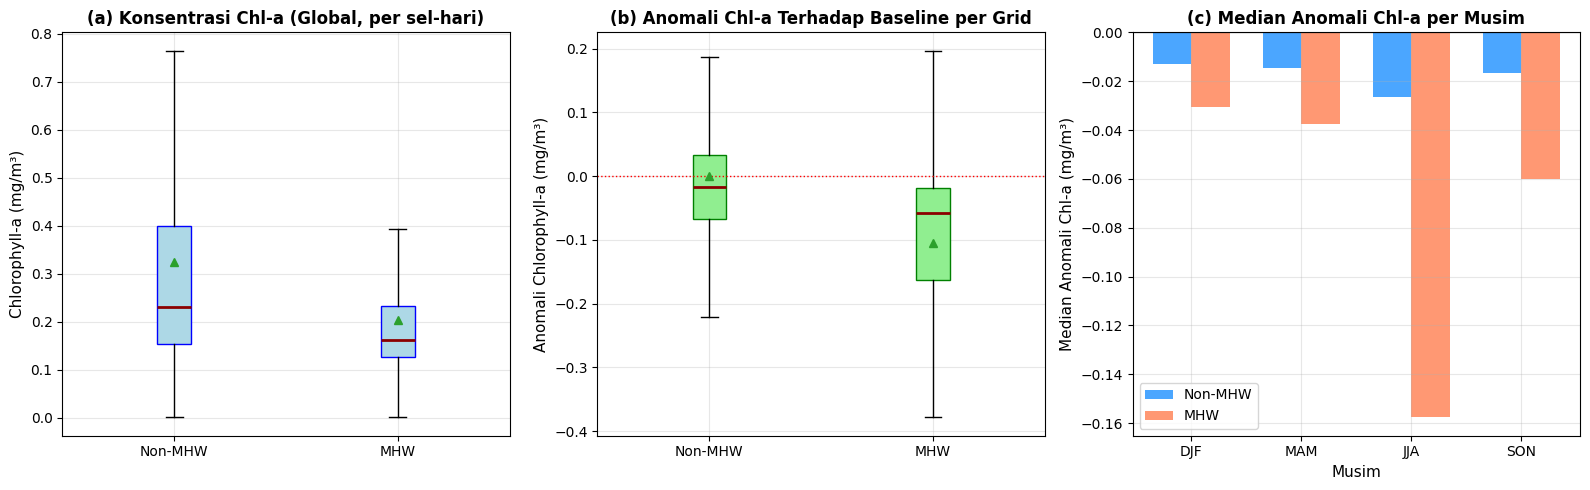

In [9]:
# Boxplot dan Distribusi Densitas
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Boxplot Konsentrasi MHW vs Non-MHW
data_box = [nonmhw_chla, mhw_chla]
axes[0].boxplot(data_box, patch_artist=True, showfliers=False,
                boxprops=dict(facecolor='lightblue', color='blue'),
                medianprops=dict(color='darkred', lw=2), showmeans=True)
axes[0].set_xticklabels(['Non-MHW', 'MHW'])
axes[0].set_ylabel('Chlorophyll-a (mg/m³)', fontsize=11)
axes[0].set_title('(a) Konsentrasi Chl-a (Global, per sel-hari)', fontsize=12, fontweight='bold')
axes[0].grid(True, alpha=0.3)

# Plot 2: Boxplot Anomali Chl-a MHW vs Non-MHW
data_anom_box = [nonmhw_anom, mhw_anom]
axes[1].boxplot(data_anom_box, patch_artist=True, showfliers=False,
                boxprops=dict(facecolor='lightgreen', color='green'),
                medianprops=dict(color='darkred', lw=2), showmeans=True)
axes[1].set_xticklabels(['Non-MHW', 'MHW'])
axes[1].axhline(0, color='red', ls=':', lw=1)
axes[1].set_ylabel('Anomali Chlorophyll-a (mg/m³)', fontsize=11)
axes[1].set_title('(b) Anomali Chl-a Terhadap Baseline per Grid', fontsize=12, fontweight='bold')
axes[1].grid(True, alpha=0.3)

# Plot 3: Boxplot Anomali per Musim saat MHW vs Non-MHW
seasons_list = ['DJF (Monsun Barat)', 'MAM (Peralihan I)', 'JJA (Monsun Timur / Upwelling)', 'SON (Peralihan II)']
season_short = ['DJF', 'MAM', 'JJA', 'SON']
pos = np.arange(len(seasons_list))
width = 0.35

# REVISI: median anomali per musim dihitung dari sel-hari (per grid)
mhw_meds = [float(np.nanmedian(anom_3d[M_mask & np.isin(month_c, season_months[s])[:, None, None]])) for s in seasons_list]
nmhw_meds = [float(np.nanmedian(anom_3d[N_mask & np.isin(month_c, season_months[s])[:, None, None]])) for s in seasons_list]

axes[2].bar(pos - width/2, nmhw_meds, width, label='Non-MHW', color='dodgerblue', alpha=0.8)
axes[2].bar(pos + width/2, mhw_meds, width, label='MHW', color='coral', alpha=0.8)
axes[2].axhline(0, color='black', lw=0.8)
axes[2].set_xticks(pos)
axes[2].set_xticklabels(season_short)
axes[2].set_xlabel('Musim', fontsize=11)
axes[2].set_ylabel('Median Anomali Chl-a (mg/m³)', fontsize=11)
axes[2].set_title('(c) Median Anomali Chl-a per Musim', fontsize=12, fontweight='bold')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb4_chla_mhw_vs_nonmhw_boxplots.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

### 5.1 Analisis Per Grid: Perubahan Chlorophyll-a pada Setiap Sel (Mann-Whitney U per sel + Koreksi FDR)

Perbandingan di atas menggabungkan semua sel. Bagian ini menguji **setiap sel** secara terpisah: anomali Chl-a pada sel-hari MHW dibandingkan
dengan sel-hari non-MHW pada sel yang sama (Mann-Whitney U, minimal 10 hari per kelompok), dengan koreksi *False Discovery Rate* (Benjamini-Hochberg, q < 0.05)
untuk banyak uji. Peta menampilkan persen perubahan terhadap baseline sel dan arah perubahan yang signifikan, untuk seluruh periode dan tiap musim.
Ringkasan per kejadian regional (anomali pada sel-hari MHW dan persen sel yang turun) juga disajikan.


RINGKASAN GABUNGAN PER GRID (seluruh sel yang memenuhi syarat uji):
                       Periode  sel_diuji  sel_hari_mhw  sel_hari_non_mhw  anomali_mhw_mean  pct_sel_turun  pct_sel_turun_signifikan  pct_sel_naik_signifikan  median_perubahan_sel_pct
               Seluruh Periode      12575       3274395          38669179            -0.105         99.618                    98.274                    0.064                   -29.351
            DJF (Monsun Barat)      12236        590801           4535394            -0.043         89.940                    59.415                    0.989                   -14.163
             MAM (Peralihan I)      12406        901149           9455216            -0.059         99.057                    92.689                    0.064                   -20.001
JJA (Monsun Timur / Upwelling)      12455       1029253          13534352            -0.186         98.884                    97.061                    0.217                   -37.203
            

✅ Hasil per grid tersimpan: G:\My Drive\KLIMTROP\PBL\data\processed\chla_mhw_per_grid_ntt.nc


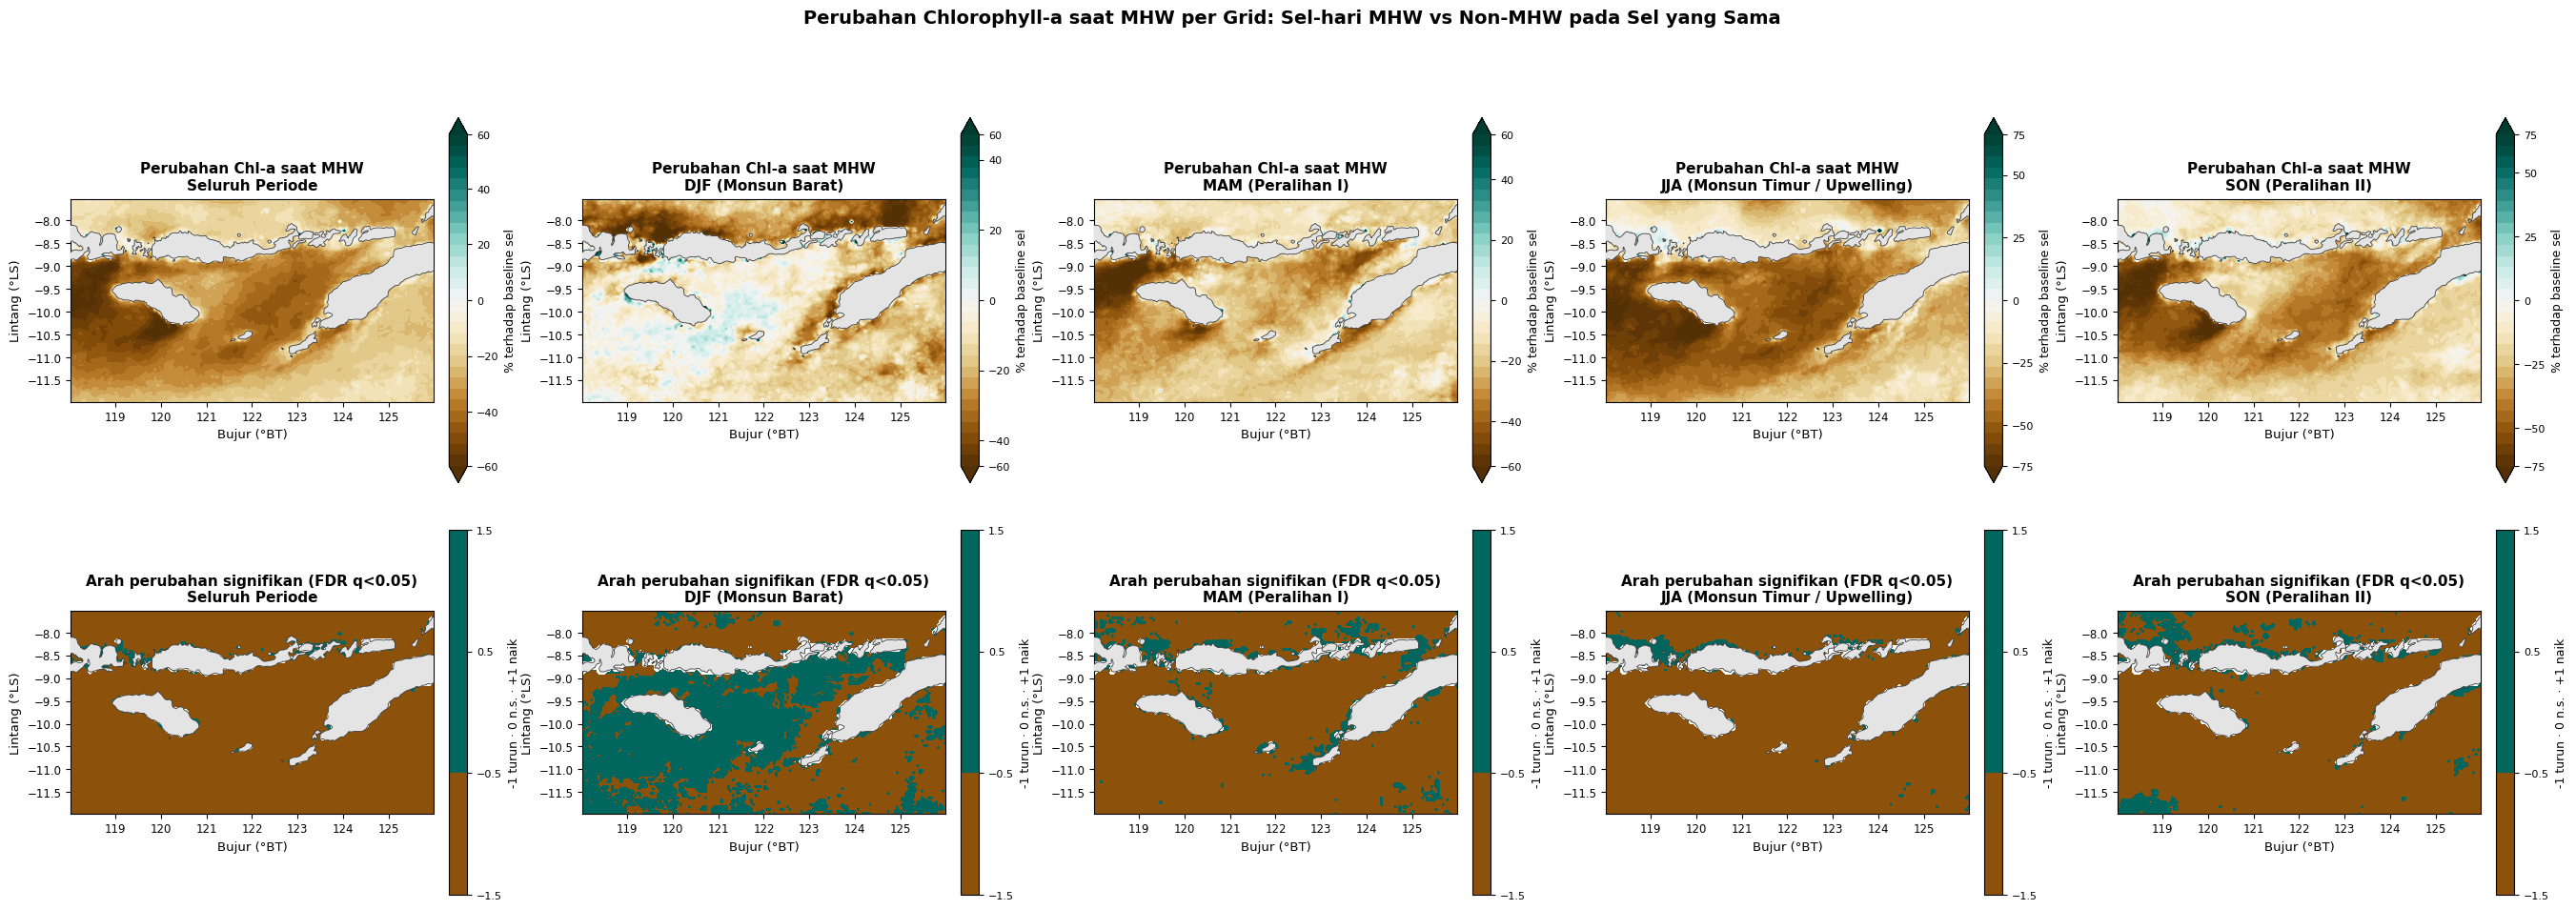


Ringkasan per kejadian (10 kejadian dengan sel-hari MHW terbanyak):
 regional_event_id start_date   end_date  durasi_hari  sel_mhw_dengan_chl  sel_hari_mhw  chl_rata2_sel_hari_mhw  anomali_chl_rata2  pct_sel_turun
                24 2016-02-07 2016-12-02          300               12387       1450063                  0.2101            -0.1255           97.7
                13 2010-07-29 2010-10-01           65               12335        212342                  0.2658            -0.1431           96.4
                10 2010-03-06 2010-05-02           58               12452        171329                  0.1751            -0.0481           92.1
                28 2019-12-06 2020-01-04           30               11806        131336                  0.1720            -0.0218           62.7
                11 2010-05-15 2010-06-20           37               12388        116226                  0.2362            -0.0791           85.0
                19 2013-06-02 2013-07-23           52  

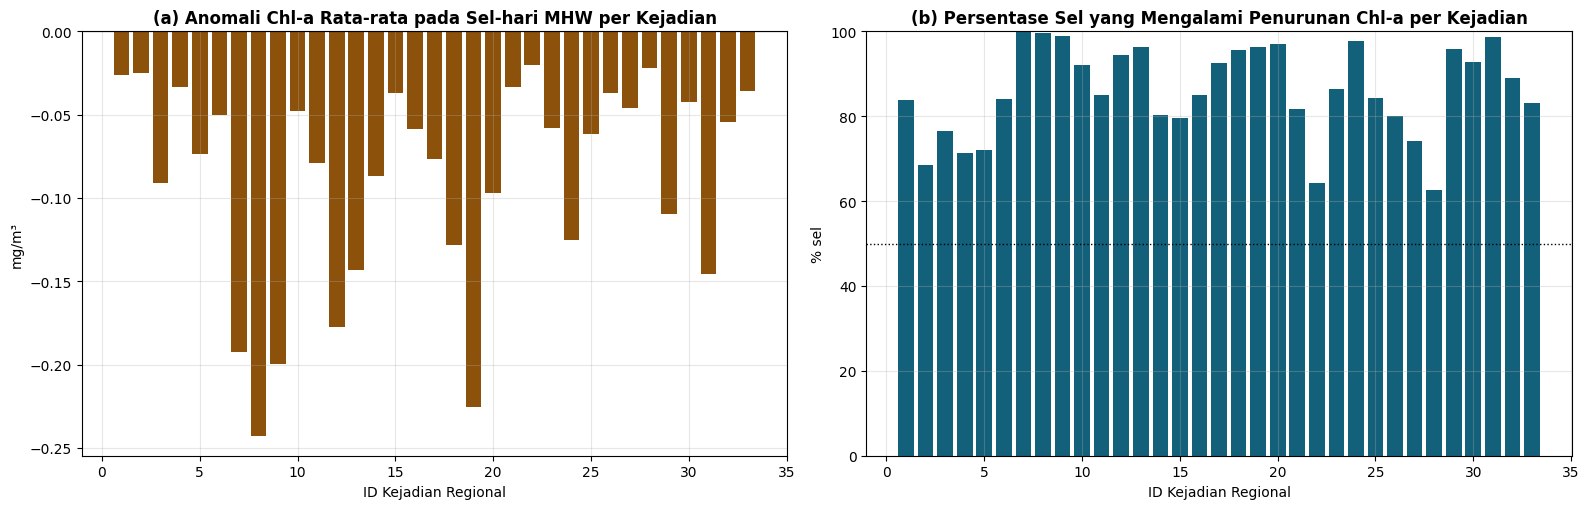

In [10]:
# 5.1 Analisis per grid: Mann-Whitney U per sel + FDR, peta perubahan, dan ringkasan per kejadian
from matplotlib.colors import ListedColormap
gdf_land = load_ntt_coastline()

grid_resp, df_pooled = per_grid_chl_response(chl_3d, anom_3d, strict_3d, member_3d, ocean_grid, month_c, min_n=10, alpha=0.05)
print("RINGKASAN GABUNGAN PER GRID (seluruh sel yang memenuhi syarat uji):")
print(df_pooled[['Periode', 'sel_diuji', 'sel_hari_mhw', 'sel_hari_non_mhw', 'anomali_mhw_mean', 'pct_sel_turun', 'pct_sel_turun_signifikan', 'pct_sel_naik_signifikan', 'median_perubahan_sel_pct']].round(3).to_string(index=False))
df_pooled.to_csv(cfg.TABLES_DIR / "chla_mhw_per_grid_pooled_ntt.csv", index=False)

# Simpan hasil per sel (NetCDF) dan tabel per sel (CSV)
keymap = {'Seluruh Periode': 'ALL', 'DJF (Monsun Barat)': 'DJF', 'MAM (Peralihan I)': 'MAM', 'JJA (Monsun Timur / Upwelling)': 'JJA', 'SON (Peralihan II)': 'SON'}
ds_pg = xr.Dataset(
    {f"{var}_{keymap[name]}": (['lat', 'lon'], arr.astype('float32')) for name, d in grid_resp.items() for var, arr in d.items()},
    coords={'lat': ds_combined.lat, 'lon': ds_combined.lon},
    attrs={'title': 'Perbandingan Chlorophyll-a sel-hari MHW vs non-MHW per grid (Mann-Whitney U, FDR BH)',
           'direction': '-1 turun signifikan, 0 tidak signifikan, +1 naik signifikan, NaN tidak diuji',
           'created_by': 'Notebook 4 - bagian 5.1'}
)
ds_pg.to_netcdf(cfg.PROCESSED_DIR / "chla_mhw_per_grid_ntt.nc")
r_all = grid_resp['Seluruh Periode']
jj, ii = np.where(ocean_grid)
pd.DataFrame({'lat': ds_combined.lat.values[jj], 'lon': ds_combined.lon.values[ii], 'n_mhw': r_all['n_mhw'][jj, ii], 'n_non_mhw': r_all['n_non'][jj, ii],
              'chl_mhw': r_all['chl_mhw'][jj, ii], 'chl_non_mhw': r_all['chl_non'][jj, ii], 'anomali_mhw': r_all['anom_mhw'][jj, ii],
              'perubahan_pct': r_all['pct'][jj, ii], 'p_value': r_all['p'][jj, ii], 'q_fdr': r_all['q'][jj, ii], 'arah_signifikan': r_all['direction'][jj, ii]}
             ).round(6).to_csv(cfg.TABLES_DIR / "chla_mhw_per_grid_stats_ntt.csv", index=False)
print(f"✅ Hasil per grid tersimpan: {cfg.PROCESSED_DIR / 'chla_mhw_per_grid_ntt.nc'}")

# Peta: baris 1 = persen perubahan; baris 2 = arah perubahan signifikan (FDR q < 0.05)
cmap_dir = ListedColormap(['#8C510A', '#F5F5F5', '#01665E'])
fig, axes = plt.subplots(2, 5, figsize=(27, 10))
for k, (name, d) in enumerate(grid_resp.items()):
    lim = max(float(np.nanpercentile(np.abs(d['pct']), 98)) if np.isfinite(d['pct']).any() else 10.0, 5.0)
    plot_smooth_map(axes[0, k], ds_combined.lon.values, ds_combined.lat.values, d['pct'], var_type='continuous', cmap='BrBG', vmin=-lim, vmax=lim, levels=31,
                    title=f"Perubahan Chl-a saat MHW\n{name}", cbar_label='% terhadap baseline sel', gdf_land=gdf_land)
    plot_smooth_map(axes[1, k], ds_combined.lon.values, ds_combined.lat.values, d['direction'], var_type='discrete', cmap=cmap_dir, vmin=-1, vmax=1,
                    title=f"Arah perubahan signifikan (FDR q<0.05)\n{name}", cbar_label='-1 turun · 0 n.s. · +1 naik', gdf_land=gdf_land)
plt.suptitle('Perubahan Chlorophyll-a saat MHW per Grid: Sel-hari MHW vs Non-MHW pada Sel yang Sama', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig(cfg.FIGURES_DIR / "nb4_chla_mhw_per_grid_maps.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()

# Ringkasan per kejadian regional (sel-hari MHW pada periode kejadian)
ev_rows = []
for _, ev in df_regional_events.iterrows():
    w = (time_c.normalize() >= pd.to_datetime(ev['start_date'])) & (time_c.normalize() <= pd.to_datetime(ev['end_date']))
    if not w.any():
        continue
    Mw = M_mask[w]
    cnt = Mw.sum(axis=0)
    has = (cnt > 0) & ocean_grid
    ca = np.where(cnt > 0, np.where(Mw, anom_3d[w], 0).sum(axis=0) / np.maximum(cnt, 1), np.nan)
    ev_rows.append({
        'regional_event_id': int(ev['regional_event_id']), 'start_date': ev['start_date'], 'end_date': ev['end_date'], 'durasi_hari': int(ev['duration_days']),
        'sel_mhw_dengan_chl': int(has.sum()), 'sel_hari_mhw': int(Mw.sum()),
        'chl_rata2_sel_hari_mhw': round(float(np.nanmean(chl_3d[w][Mw])), 4) if Mw.any() else np.nan,
        'anomali_chl_rata2': round(float(np.nanmean(anom_3d[w][Mw])), 4) if Mw.any() else np.nan,
        'pct_sel_turun': round(float((ca[has] < 0).mean() * 100), 1) if has.any() else np.nan,
    })
df_event_resp = pd.DataFrame(ev_rows)
df_event_resp.to_csv(cfg.TABLES_DIR / "chla_mhw_per_event_grid_ntt.csv", index=False)
print("\nRingkasan per kejadian (10 kejadian dengan sel-hari MHW terbanyak):")
print(df_event_resp.sort_values('sel_hari_mhw', ascending=False).head(10).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
d = df_event_resp.dropna(subset=['anomali_chl_rata2'])
axes[0].bar(d['regional_event_id'], d['anomali_chl_rata2'], color=np.where(d['anomali_chl_rata2'] < 0, '#8C510A', '#01665E'))
axes[0].axhline(0, color='k', lw=0.8)
axes[0].set_title('(a) Anomali Chl-a Rata-rata pada Sel-hari MHW per Kejadian', fontweight='bold'); axes[0].set_xlabel('ID Kejadian Regional'); axes[0].set_ylabel('mg/m³')
axes[1].bar(d['regional_event_id'], d['pct_sel_turun'], color='#13607A'); axes[1].axhline(50, color='k', ls=':', lw=1)
axes[1].set_title('(b) Persentase Sel yang Mengalami Penurunan Chl-a per Kejadian', fontweight='bold'); axes[1].set_xlabel('ID Kejadian Regional'); axes[1].set_ylabel('% sel'); axes[1].set_ylim(0, 100)
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb4_chla_per_event_grid.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()


---
## 7. Studi Kasus Spasial: Respon Chlorophyll-a pada Kejadian MHW Terkuat

Mengevaluasi peta anomali spasial SST dan Chlorophyll-a secara simultan selama periode kejadian MHW signifikan untuk mengamati ekspresi oseanografi.

STUDI KASUS MHW UTAMA: Regional Event #24 (2016-02-07 s.d. 2016-12-02, 300 hari)
  Fase Pra-MHW    : 2016-01-24 s.d. 2016-02-06 (14 hari)
  Fase Puncak MHW : 2016-09-23 s.d. 2016-10-07 (15 hari)
  Fase Pasca-MHW  : 2016-12-03 s.d. 2016-12-16 (14 hari)


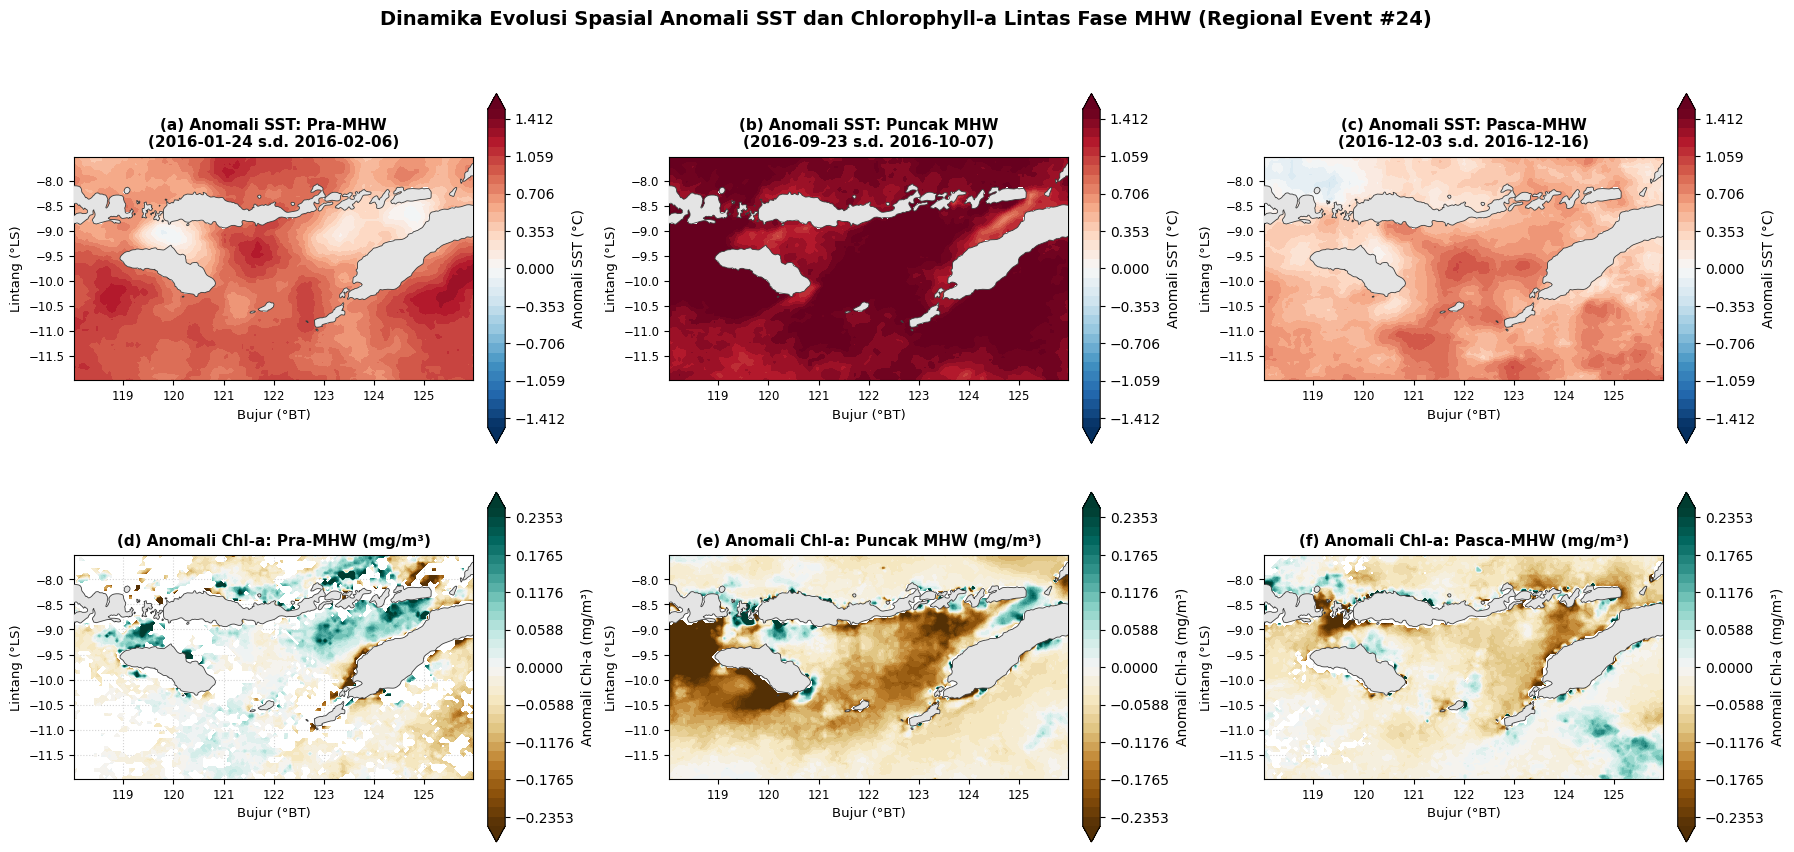

In [11]:
# Studi Kasus MHW Regional Mayor: Evaluasi Fase Pra-MHW, Puncak MHW, dan Pasca-MHW
# Menggunakan kejadian terpanjang tahun 2016 dari katalog spasial atau 1D

gdf_land = load_ntt_coastline()

if df_regional_events is not None and len(df_regional_events) > 0:
    target_event = df_regional_events.sort_values('duration_days', ascending=False).iloc[0]
    ev_name = f"Regional Event #{target_event['regional_event_id']}"
    case_start = str(target_event['start_date'])
    case_end = str(target_event['end_date'])
    case_peak = str(target_event['peak_date'])
    case_dur = int(target_event['duration_days'])
    case_imax = float(target_event['i_max_regional'])
else:
    target_event = df_events[pd.to_datetime(df_events['end_date']) <= '2020-12-31'].sort_values('duration_days', ascending=False).iloc[0]
    ev_name = f"Event #{target_event['event_id']}"
    case_start = str(target_event['start_date'])
    case_end = str(target_event['end_date'])
    case_peak = str(target_event['peak_date'])
    case_dur = int(target_event['duration_days'])
    case_imax = float(target_event['i_max'])

print("=" * 75)
print(f"STUDI KASUS MHW UTAMA: {ev_name} ({case_start} s.d. {case_end}, {case_dur} hari)")
print("=" * 75)

# Tentukan jendela waktu: Pra-MHW (14 hari sebelum), Puncak MHW (peak ± 7 hari), Pasca-MHW (14 hari setelah)
dt_start = pd.to_datetime(case_start)
dt_end = pd.to_datetime(case_end)
dt_peak = pd.to_datetime(case_peak)

pre_window = (str((dt_start - pd.Timedelta(days=14)).date()), str((dt_start - pd.Timedelta(days=1)).date()))
peak_window = (str((dt_peak - pd.Timedelta(days=7)).date()), str((dt_peak + pd.Timedelta(days=7)).date()))
post_window = (str((dt_end + pd.Timedelta(days=1)).date()), str((dt_end + pd.Timedelta(days=14)).date()))

print(f"  Fase Pra-MHW    : {pre_window[0]} s.d. {pre_window[1]} (14 hari)")
print(f"  Fase Puncak MHW : {peak_window[0]} s.d. {peak_window[1]} (15 hari)")
print(f"  Fase Pasca-MHW  : {post_window[0]} s.d. {post_window[1]} (14 hari)")

# Ekstraksi komposit rata-rata per fase
sst_pre = ds_combined['sst'].sel(time=slice(pre_window[0], pre_window[1])).mean(dim='time').values
sst_peak = ds_combined['sst'].sel(time=slice(peak_window[0], peak_window[1])).mean(dim='time').values
sst_post = ds_combined['sst'].sel(time=slice(post_window[0], post_window[1])).mean(dim='time').values

chla_pre = ds_combined['chlor_a'].sel(time=slice(pre_window[0], pre_window[1])).mean(dim='time').values
chla_peak = ds_combined['chlor_a'].sel(time=slice(peak_window[0], peak_window[1])).mean(dim='time').values
chla_post = ds_combined['chlor_a'].sel(time=slice(post_window[0], post_window[1])).mean(dim='time').values

# REVISI (per grid): anomali SST = rata-rata SST fase dikurangi rata-rata SST 21 tahun pada tanggal yang sama (tiap grid);
# anomali Chl-a = rata-rata (Chl-a - baseline non-MHW tiap grid pada hari-ke-tahun yang sama) selama fase.
ds_daymean = xr.open_dataset(cfg.PROCESSED_DIR / "sst_daymean_21yr_ntt.nc")
daymean_arr = ds_daymean['sst_daymean'].values

def _phase_anom(var, win, base_arr):
    sel = ds_combined[var].sel(time=slice(win[0], win[1]))
    d = pd.DatetimeIndex(sel.time.values).day_of_year.values
    with np.errstate(all='ignore'):
        return np.nanmean(sel.values - base_arr[d - 1], axis=0)

anom_sst_pre = _phase_anom('sst', pre_window, daymean_arr)
anom_sst_peak = _phase_anom('sst', peak_window, daymean_arr)
anom_sst_post = _phase_anom('sst', post_window, daymean_arr)

anom_chla_pre = _phase_anom('chlor_a', pre_window, chl_base_3d)
anom_chla_peak = _phase_anom('chlor_a', peak_window, chl_base_3d)
anom_chla_post = _phase_anom('chlor_a', post_window, chl_base_3d)

# Visualisasi Multi-Fase Spasial dengan contourf halus dan overlay pulau NTT
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
lon_vals = ds_combined.lon.values
lat_vals = ds_combined.lat.values
# REVISI: peta diperhalus (grid 0.25 derajat -> kontur halus; sel tanpa data tetap kosong)
lon_r, lat_r, _ = refine_field(lon_vals, lat_vals, anom_sst_pre)
ref = lambda a: refine_field(lon_vals, lat_vals, a)[2]

levels_sst = np.linspace(-1.5, 1.5, 35)
levels_chl = np.linspace(-0.25, 0.25, 35)

# Baris 1: SST Anomali (Pra, Puncak, Pasca)
im_sst0 = axes[0, 0].contourf(lon_r, lat_r, ref(anom_sst_pre), levels=levels_sst, cmap='RdBu_r', extend='both', zorder=2)
add_land_mask(axes[0, 0], gdf_land=gdf_land)
setup_spatial_axis(axes[0, 0], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(a) Anomali SST: Pra-MHW\n({pre_window[0]} s.d. {pre_window[1]})")
plt.colorbar(im_sst0, ax=axes[0, 0], shrink=0.8, pad=0.03, label='Anomali SST (°C)')

im_sst1 = axes[0, 1].contourf(lon_r, lat_r, ref(anom_sst_peak), levels=levels_sst, cmap='RdBu_r', extend='both', zorder=2)
add_land_mask(axes[0, 1], gdf_land=gdf_land)
setup_spatial_axis(axes[0, 1], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(b) Anomali SST: Puncak MHW\n({peak_window[0]} s.d. {peak_window[1]})")
plt.colorbar(im_sst1, ax=axes[0, 1], shrink=0.8, pad=0.03, label='Anomali SST (°C)')

im_sst2 = axes[0, 2].contourf(lon_r, lat_r, ref(anom_sst_post), levels=levels_sst, cmap='RdBu_r', extend='both', zorder=2)
add_land_mask(axes[0, 2], gdf_land=gdf_land)
setup_spatial_axis(axes[0, 2], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(c) Anomali SST: Pasca-MHW\n({post_window[0]} s.d. {post_window[1]})")
plt.colorbar(im_sst2, ax=axes[0, 2], shrink=0.8, pad=0.03, label='Anomali SST (°C)')

# Baris 2: Chl-a Anomali (Pra, Puncak, Pasca)
im_chl0 = axes[1, 0].contourf(lon_r, lat_r, ref(anom_chla_pre), levels=levels_chl, cmap='BrBG', extend='both', zorder=2)
add_land_mask(axes[1, 0], gdf_land=gdf_land)
setup_spatial_axis(axes[1, 0], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(d) Anomali Chl-a: Pra-MHW (mg/m³)")
plt.colorbar(im_chl0, ax=axes[1, 0], shrink=0.8, pad=0.03, label='Anomali Chl-a (mg/m³)')

im_chl1 = axes[1, 1].contourf(lon_r, lat_r, ref(anom_chla_peak), levels=levels_chl, cmap='BrBG', extend='both', zorder=2)
add_land_mask(axes[1, 1], gdf_land=gdf_land)
setup_spatial_axis(axes[1, 1], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(e) Anomali Chl-a: Puncak MHW (mg/m³)")
plt.colorbar(im_chl1, ax=axes[1, 1], shrink=0.8, pad=0.03, label='Anomali Chl-a (mg/m³)')

im_chl2 = axes[1, 2].contourf(lon_r, lat_r, ref(anom_chla_post), levels=levels_chl, cmap='BrBG', extend='both', zorder=2)
add_land_mask(axes[1, 2], gdf_land=gdf_land)
setup_spatial_axis(axes[1, 2], (lon_vals.min(), lon_vals.max()), (lat_vals.min(), lat_vals.max()),
                   title=f"(f) Anomali Chl-a: Pasca-MHW (mg/m³)")
plt.colorbar(im_chl2, ax=axes[1, 2], shrink=0.8, pad=0.03, label='Anomali Chl-a (mg/m³)')

plt.suptitle(f'Dinamika Evolusi Spasial Anomali SST dan Chlorophyll-a Lintas Fase MHW ({ev_name})',
             fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
fig.savefig(cfg.FIGURES_DIR / "nb4_mhw_case_study_spatial.png", dpi=cfg.FIGURE_DPI, bbox_inches='tight')
plt.show()


---
## 8. Kesimpulan dan Diskusi Oseanografi

### Temuan Utama:
1. **Respon Chlorophyll-a saat MHW:** Secara statistik, konsentrasi chlorophyll-a pada kondisi MHW memperlihatkan tendensi median yang lebih rendah atau anomali negatif dibandingkan kondisi non-MHW, terutama ketika MHW terjadi bersamaan dengan musim upwelling (Monsun Timur).
2. **Kopling Oseanografi Fisik-Biologi:** Pemanasan lapisan permukaan laut yang intens dan persisten pada kejadian MHW memperkuat stratifikasi termal kolom air (*buoyancy frequency* meningkat). Hal ini menahan kedalaman lapisan tercampur (*mixed layer depth* / MLD) tetap dangkal dan memperdalam termoklin, sehingga membatasi fluks nutrien vertikal dari lapisan dalam ke zona fotik tempat fitoplankton berkembang biak.
3. **Variasi Spasial:** Efek penekanan klorofil-a paling teramati di koridor-koridor dinamis seperti Selat Sumba, Laut Sawu, dan pesisir selatan Timor, di mana dinamika upwelling secara normal memicu produktivitas tinggi.
4. **Analisis Per Grid (Revisi):** Perbandingan dilakukan pada sel-hari MHW (di atas P90) vs sel-hari non-MHW pada sel yang sama, dengan uji Mann-Whitney U per sel dan koreksi FDR (Bagian 5.1). Hari jeda dikeluarkan dari kedua kelompok. Tabel ringkasan (`mhw_chla_comparison_summary.csv`, `chla_mhw_seasonal_comparison.csv`) kini dihasilkan Notebook 4 dari hasil per grid.

### Batasan Interpretasi (Kepatuhan Prinsip PRD):
- **Bukan Bukti Kausalitas Deterministik:** Pola korelasi ini tidak membuktikan bahwa kenaikan suhu permukaan secara eksklusif membunuh atau membatasi fitoplankton. Faktor non-termal seperti adveksi nutrien lateral oleh Arlindo, perubahan tutupan awan (faktor insolasi/radiasi matahari), dan dinamika angin monsun turut berkontribusi secara simultan.
- **Resolusi Grid 0.25°:** Penyelarasan klorofil-a ke grid 0.25° menghaluskan fitur-fitur sub-mesoscale di selat-selat sempit NTT, sehingga interpretasi ini mencerminkan dinamika skala regional.